In [1]:
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:
# A1.1 Load CIFAR-10
(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("X_train:", X_train_raw.shape, X_train_raw.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test :", X_test_raw.shape, X_test_raw.dtype)
print("y_test :", y_test.shape, y_test.dtype)
print("Unique labels:", np.unique(y_train).tolist())

X_train: (50000, 32, 32, 3) uint8
y_train: (50000, 1) uint8
X_test : (10000, 32, 32, 3) uint8
y_test : (10000, 1) uint8
Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


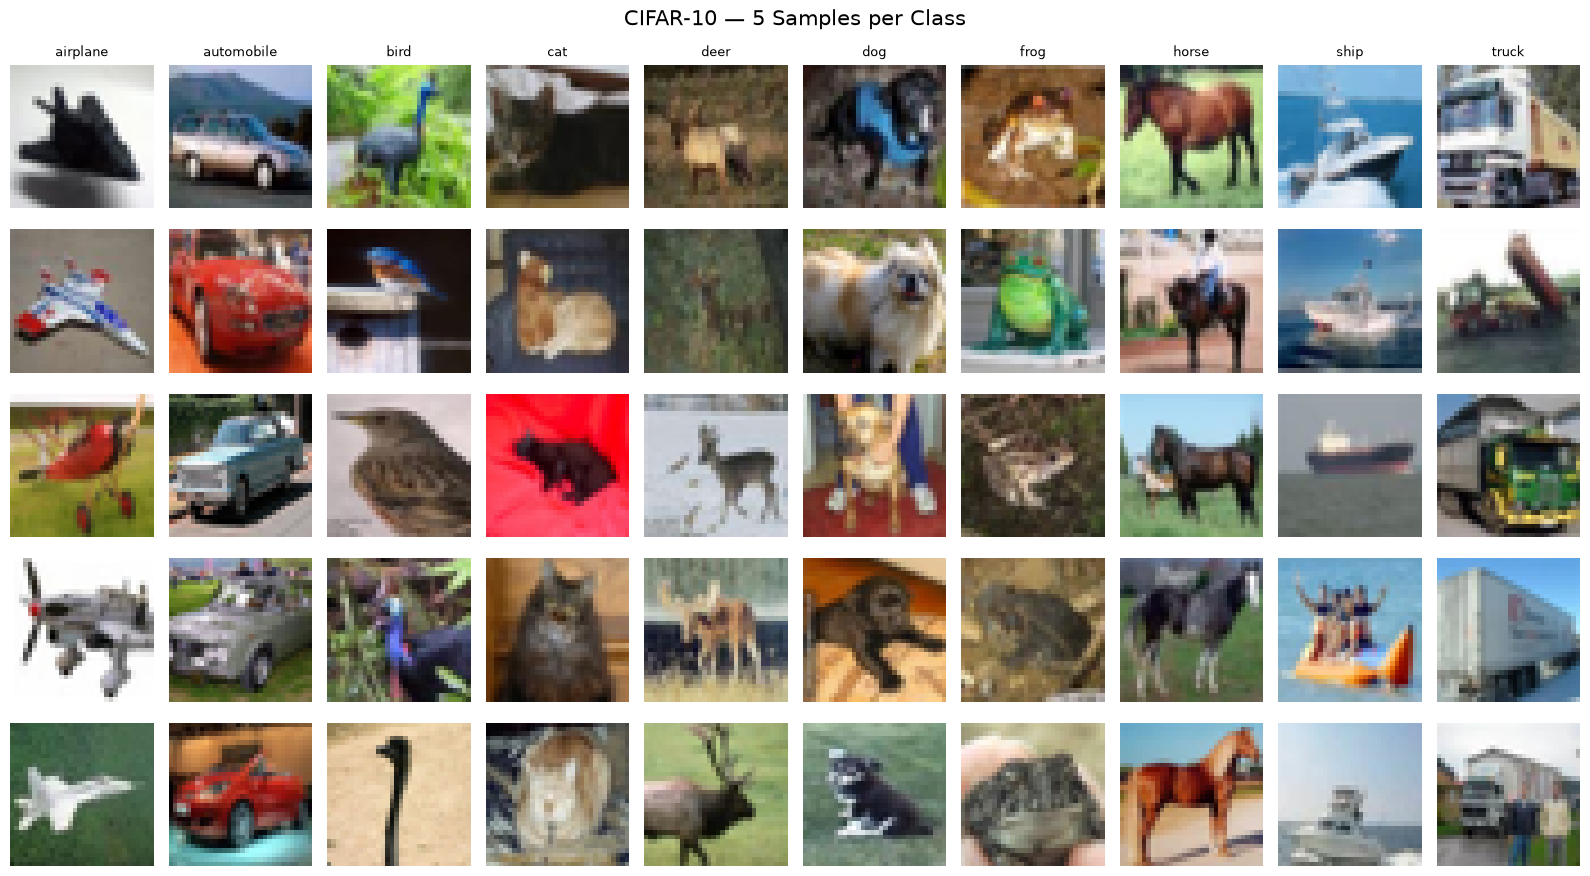

In [5]:
# A1.2 Show 5 images from each of the 10 classes (5 x 10 grid)
fig, axes = plt.subplots(5, 10, figsize=(16, 9))
for class_id in range(10):
    indices = np.where(y_train.reshape(-1) == class_id)[0][:5]
    for row, idx in enumerate(indices):
        axes[row, class_id].imshow(X_train_raw[idx])
        axes[row, class_id].axis("off")
        if row == 0:
            axes[row, class_id].set_title(class_names[class_id], fontsize=9)
fig.suptitle("CIFAR-10 — 5 Samples per Class", fontsize=15)
plt.tight_layout()
plt.show()

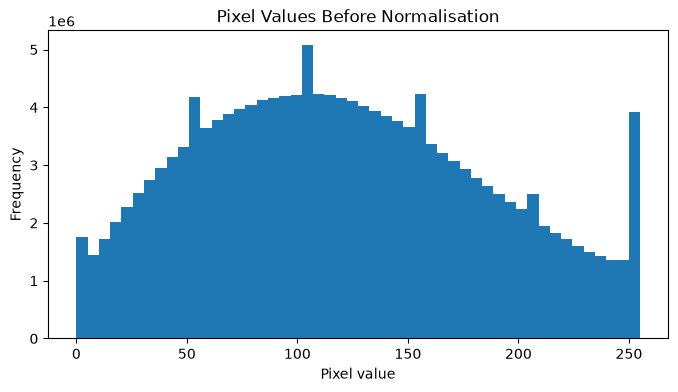

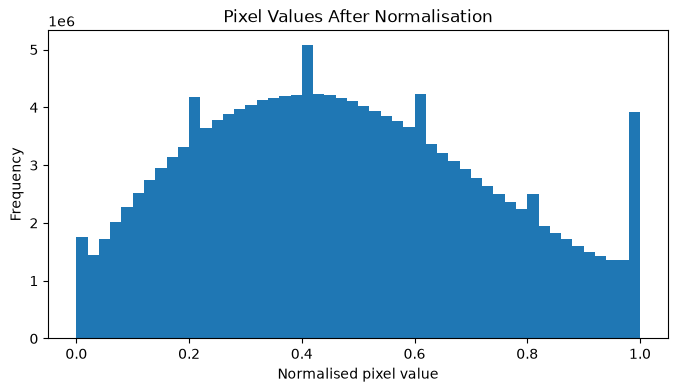

Normalised range: 0.0 to 1.0


In [6]:
# A1.3 Pixel distribution before normalisation
plt.figure(figsize=(8, 4))
plt.hist(X_train_raw.flatten(), bins=50)
plt.title("Pixel Values Before Normalisation")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()

# Normalise pixel values from [0, 255] to [0, 1]
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

plt.figure(figsize=(8, 4))
plt.hist(X_train.flatten(), bins=50)
plt.title("Pixel Values After Normalisation")
plt.xlabel("Normalised pixel value")
plt.ylabel("Frequency")
plt.show()

print("Normalised range:", float(X_train.min()), "to", float(X_train.max()))

In [7]:
# A1.4 One-hot encode the labels
y_train_ohe = keras.utils.to_categorical(y_train, num_classes=10)
y_test_ohe = keras.utils.to_categorical(y_test, num_classes=10)

print("One-hot training labels:", y_train_ohe.shape)
print("One-hot test labels:", y_test_ohe.shape)
print("Example label:", y_train[0, 0], "->", y_train_ohe[0])

One-hot training labels: (50000, 10)
One-hot test labels: (10000, 10)
Example label: 6 -> [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


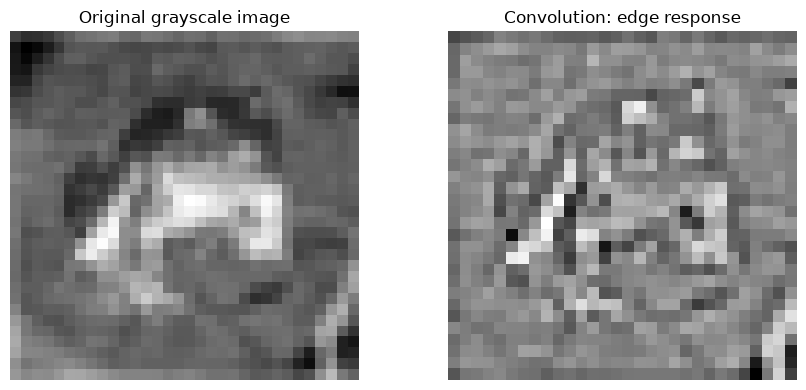

In [8]:
# A2.1 Manual convolution using a simple edge-detection kernel
from scipy.signal import convolve2d

gray = np.mean(X_train_raw[0], axis=2).astype("float32")
edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype="float32")

edge_result = convolve2d(gray, edge_kernel, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original grayscale image")
axes[1].imshow(edge_result, cmap="gray")
axes[1].set_title("Convolution: edge response")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

padding=valid, stride=1: output shape = (1, 30, 30, 8)
padding=same , stride=1: output shape = (1, 32, 32, 8)
padding=valid, stride=2: output shape = (1, 15, 15, 8)
padding=same , stride=2: output shape = (1, 16, 16, 8)


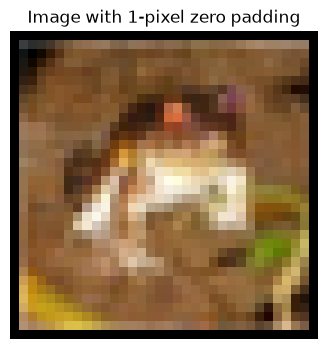

In [9]:
# A2.2 VALID vs SAME padding and A2.3 stride effects
sample_batch = X_train[:1]

def show_conv_shape(padding, stride):
    test_model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(8, kernel_size=3, strides=stride, padding=padding)
    ])
    print(f"padding={padding:5s}, stride={stride}: output shape = {test_model(sample_batch).shape}")

show_conv_shape("valid", 1)
show_conv_shape("same", 1)
show_conv_shape("valid", 2)
show_conv_shape("same", 2)

# Display a zero-padded example for illustration
padded_image = np.pad(X_train_raw[0], ((1, 1), (1, 1), (0, 0)), mode="constant")
plt.figure(figsize=(4, 4))
plt.imshow(padded_image)
plt.title("Image with 1-pixel zero padding")
plt.axis("off")
plt.show()

Feature map tensor: (32, 32, 16)


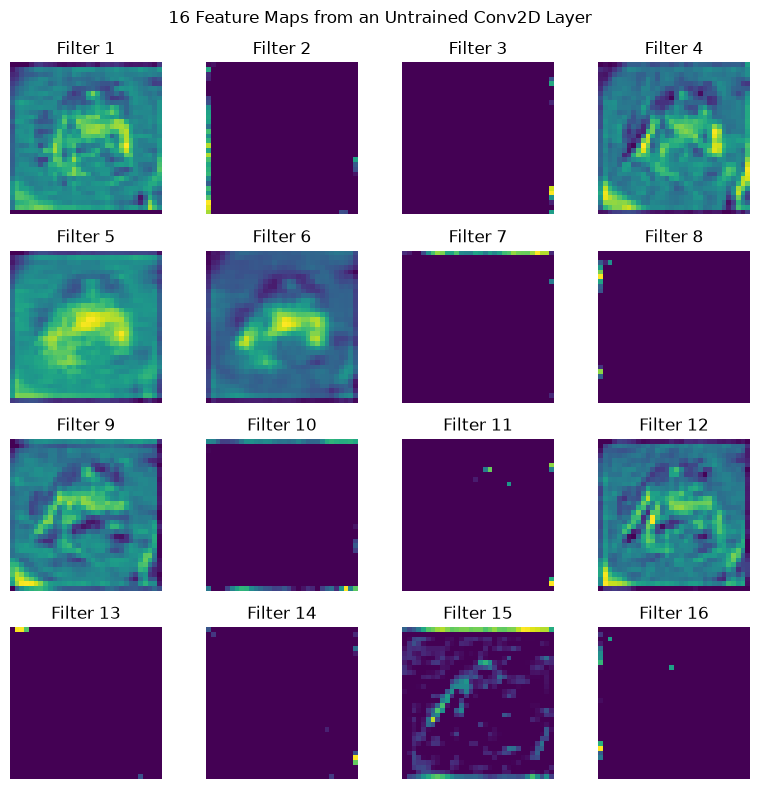

In [10]:
# A2.4 Visualise 16 feature maps from a Conv2D layer
feature_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same")
])

feature_maps = feature_model(X_train[:1], training=False).numpy()[0]
print("Feature map tensor:", feature_maps.shape)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[:, :, i], cmap="viridis")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")
fig.suptitle("16 Feature Maps from an Untrained Conv2D Layer")
plt.tight_layout()
plt.show()

Before pooling: (32, 32, 16)
After max pooling: (16, 16, 16)
After average pooling: (16, 16, 16)


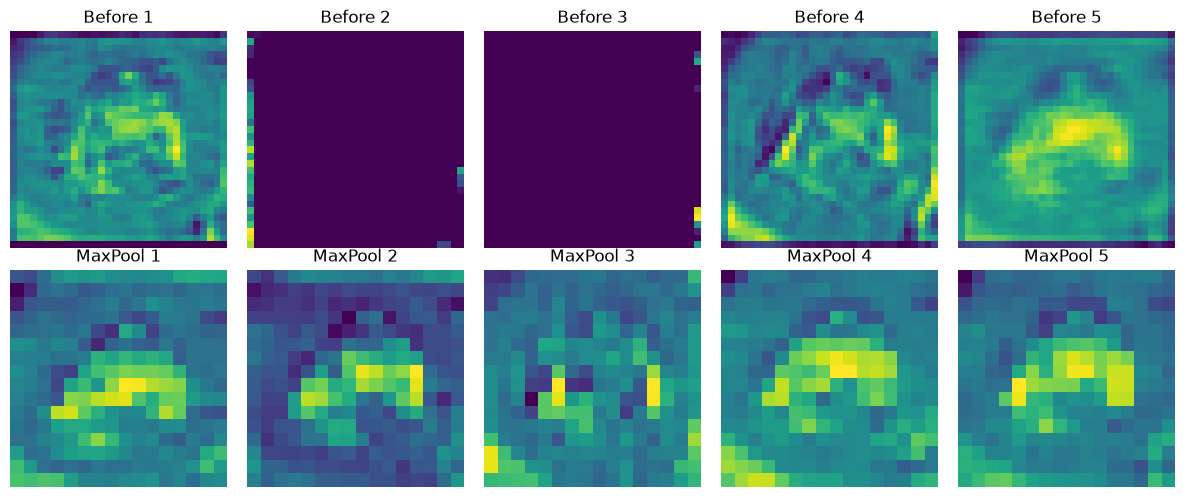

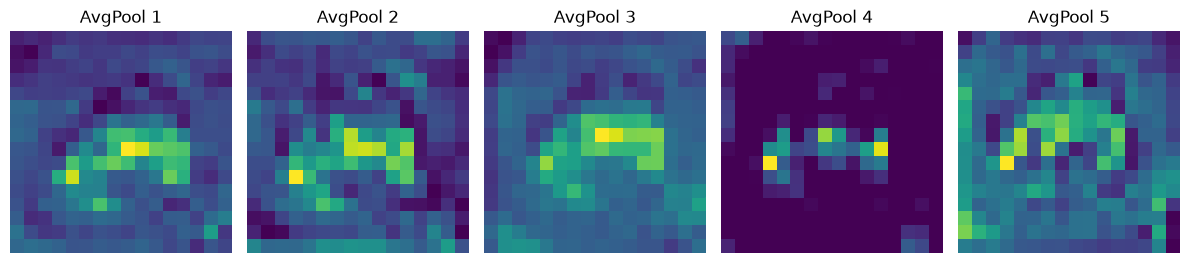

In [11]:
# A3.1 Compare MaxPooling2D and AveragePooling2D
max_pool_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2))
])
avg_pool_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, 3, activation="relu", padding="same"),
    layers.AveragePooling2D(pool_size=(2, 2))
])

pre_pool = feature_model(X_train[:1], training=False).numpy()[0]
max_pooled = max_pool_model(X_train[:1], training=False).numpy()[0]
avg_pooled = avg_pool_model(X_train[:1], training=False).numpy()[0]
print("Before pooling:", pre_pool.shape)
print("After max pooling:", max_pooled.shape)
print("After average pooling:", avg_pooled.shape)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for j in range(5):
    axes[0, j].imshow(pre_pool[:, :, j], cmap="viridis")
    axes[0, j].set_title(f"Before {j+1}")
    axes[1, j].imshow(max_pooled[:, :, j], cmap="viridis")
    axes[1, j].set_title(f"MaxPool {j+1}")
    axes[0, j].axis("off")
    axes[1, j].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for j, ax in enumerate(axes):
    ax.imshow(avg_pooled[:, :, j], cmap="viridis")
    ax.set_title(f"AvgPool {j+1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [13]:
# A3.2 Flatten shape demonstration
shape_demo = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2, 2),
    layers.Flatten()
])
print("Before Flatten: (None, 16, 16, 16)")
print("After Flatten :", shape_demo(X_train[:1]).shape)

Before Flatten: (None, 16, 16, 16)
After Flatten : (1, 4096)


In [14]:
# A3.3 LeNet-5-style architecture adapted for CIFAR-10
lenet5 = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(6, (5, 5), activation="tanh"),
    layers.AveragePooling2D((2, 2)),
    layers.Conv2D(16, (5, 5), activation="tanh"),
    layers.AveragePooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(120, activation="tanh"),
    layers.Dense(84, activation="tanh"),
    layers.Dense(10, activation="softmax")
], name="LeNet5_CIFAR10")

lenet5.summary()

Model: "LeNet5_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# A3.4 Custom modern CNN baseline (VGG-style)
def build_custom_cnn():
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, 2)(x)

    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2, 2)(x)

    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="Custom_CNN")

model_cnn = build_custom_cnn()
model_cnn.summary()
print("Total parameters:", model_cnn.count_params())

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 175018


In [16]:
# A4.2 Compile and train the scratch CNN
model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1
)

start_time = time.time()
history_cnn = model_cnn.fit(
    X_train, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)
print(f"Training time: {(time.time() - start_time)/60:.1f} minutes")

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 50s 65ms/step - accuracy: 0.3352 - loss: 1.7400 - val_accuracy: 0.4428 - val_loss: 1.4687 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 60s 85ms/step - accuracy: 0.5126 - loss: 1.3242 - val_accuracy: 0.5150 - val_loss: 1.3003 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.5943 - loss: 1.1265 - val_accuracy: 0.6084 - val_loss: 1.0942 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 36ms/step - accuracy: 0.6397 - loss: 1.0031 - val_accuracy: 0.6642 - val_loss: 0.9485 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - accuracy: 0.6724 - loss: 0.9144 - val_accuracy: 0.6902 - val_loss: 0.8828 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.6989 - loss: 0.8414 - val_accuracy: 0.7068 - val_loss: 0.8339 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.7

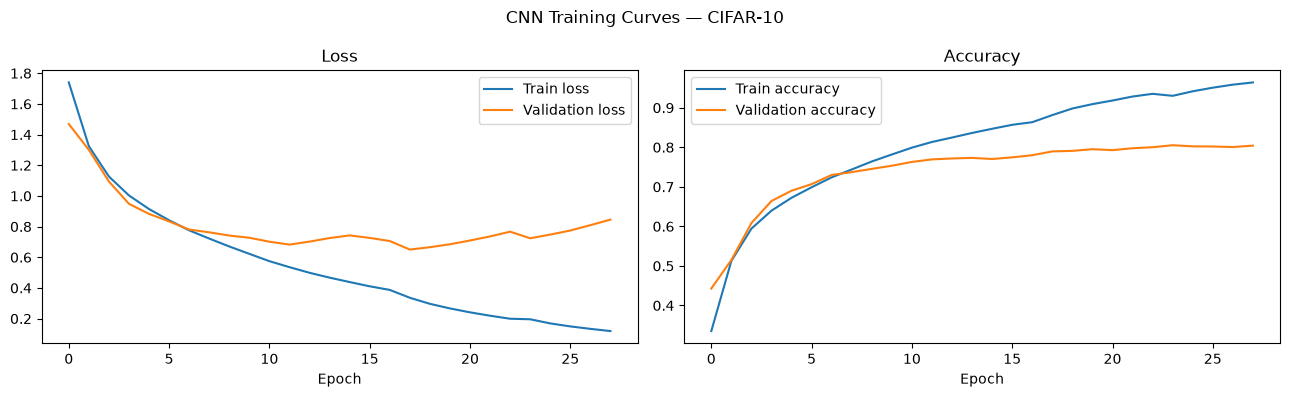

Epochs completed: 28


In [17]:
# A4.3 Plot training curves
def plot_history(history, title="Training Curves"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history.history["loss"], label="Train loss")
    axes[0].plot(history.history["val_loss"], label="Validation loss")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history.history["accuracy"], label="Train accuracy")
    axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history_cnn, "CNN Training Curves — CIFAR-10")
print("Epochs completed:", len(history_cnn.history["loss"]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7760 - loss: 0.7025
Scratch CNN test loss: 0.7025
Scratch CNN test accuracy: 0.7760 (77.60%)
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step


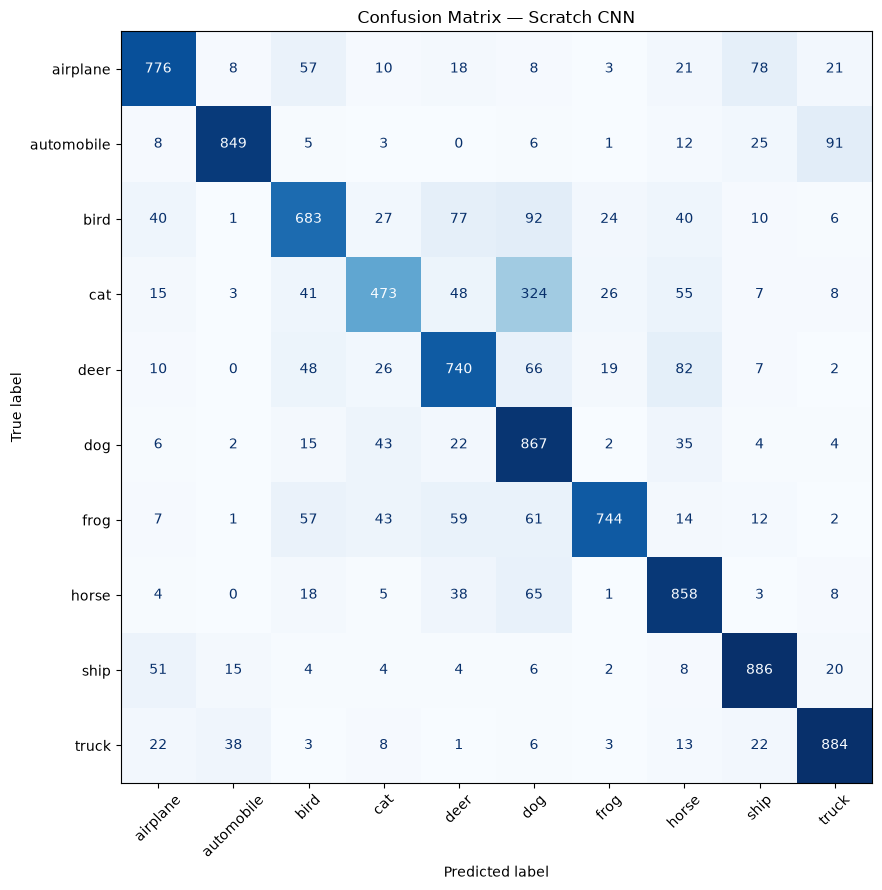

              precision    recall  f1-score   support

    airplane      0.826     0.776     0.800      1000
  automobile      0.926     0.849     0.886      1000
        bird      0.734     0.683     0.707      1000
         cat      0.737     0.473     0.576      1000
        deer      0.735     0.740     0.737      1000
         dog      0.578     0.867     0.693      1000
        frog      0.902     0.744     0.815      1000
       horse      0.754     0.858     0.803      1000
        ship      0.841     0.886     0.863      1000
       truck      0.845     0.884     0.864      1000

    accuracy                          0.776     10000
   macro avg      0.788     0.776     0.775     10000
weighted avg      0.788     0.776     0.775     10000



In [18]:
# A4.4 Evaluate model on the held-out test set
test_loss, test_accuracy = model_cnn.evaluate(X_test, y_test_ohe, verbose=1)
print(f"Scratch CNN test loss: {test_loss:.4f}")
print(f"Scratch CNN test accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

y_pred_prob = model_cnn.predict(X_test, batch_size=128, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = y_test.reshape(-1)

cm = confusion_matrix(y_true, y_pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(10, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix — Scratch CNN")
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

Top 3 most-confused class pairs:
cat / dog: 367 combined errors
automobile / truck: 129 combined errors
airplane / ship: 129 combined errors


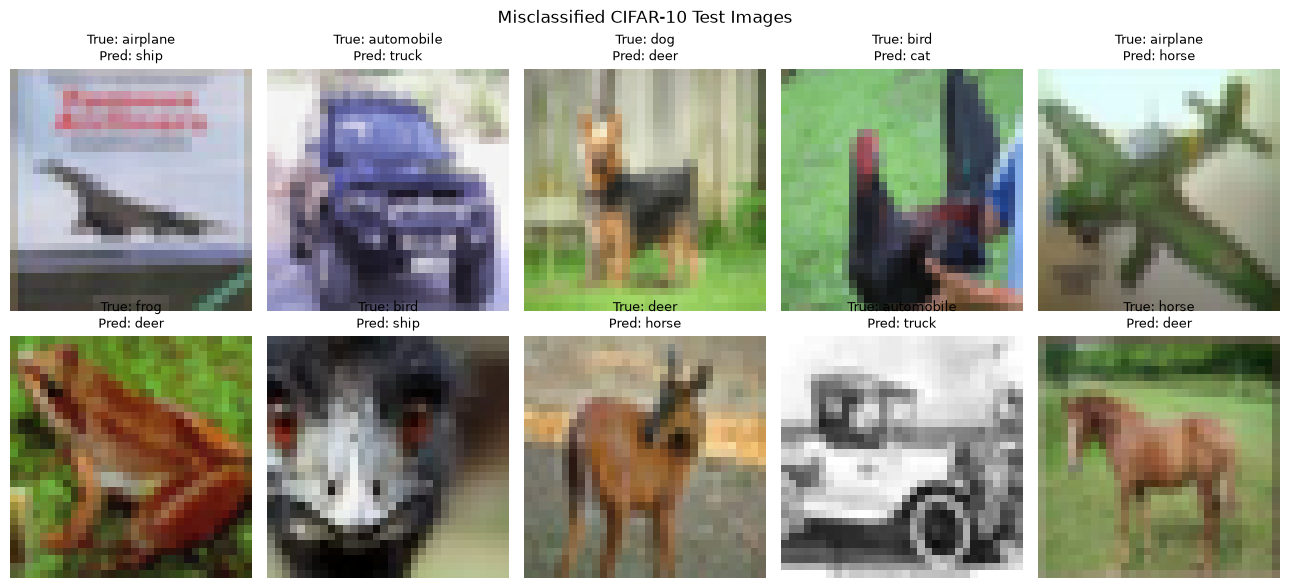

In [19]:
# Find the three most-confused class pairs (off-diagonal errors, both directions combined)
pair_errors = []
for i in range(10):
    for j in range(i + 1, 10):
        count = int(cm[i, j] + cm[j, i])
        pair_errors.append((count, class_names[i], class_names[j]))
pair_errors.sort(reverse=True)
print("Top 3 most-confused class pairs:")
for count, a, b in pair_errors[:3]:
    print(f"{a} / {b}: {count} combined errors")

# Display 10 misclassified images
wrong_indices = np.where(y_pred != y_true)[0]
n_show = min(10, len(wrong_indices))
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, idx in zip(axes.flat, wrong_indices[:n_show]):
    ax.imshow(X_test_raw[idx])
    ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=9)
    ax.axis("off")
for ax in axes.flat[n_show:]:
    ax.axis("off")
fig.suptitle("Misclassified CIFAR-10 Test Images")
plt.tight_layout()
plt.show()

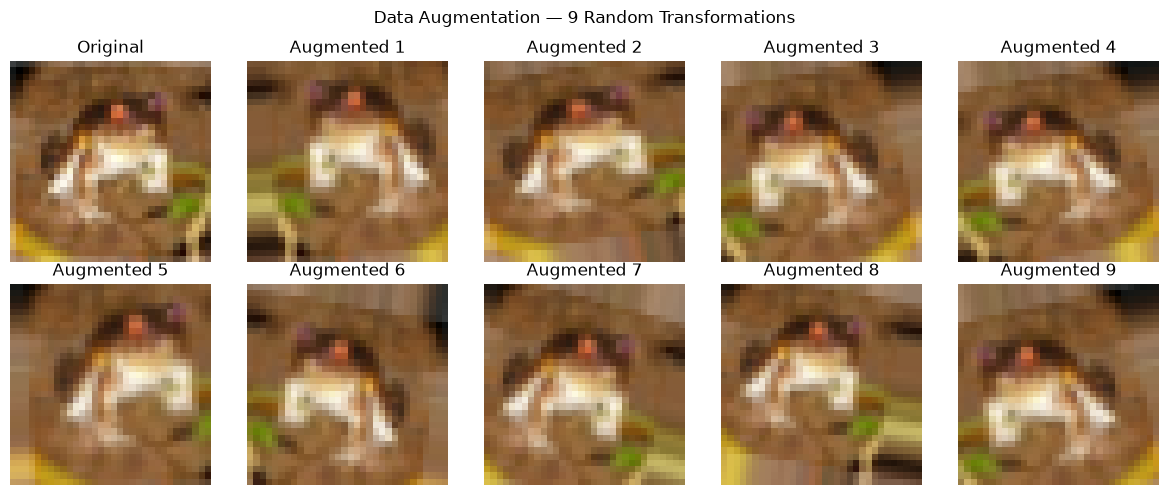

In [20]:
# A5.2 ImageDataGenerator augmentation and visualisation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)
datagen.fit(X_train)

img = X_train[0]
aug_iter = datagen.flow(img[np.newaxis, ...], batch_size=1, shuffle=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(img)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")
for i in range(1, 10):
    aug_img = next(aug_iter)[0]
    ax = axes.flat[i]
    ax.imshow(np.clip(aug_img, 0, 1))
    ax.set_title(f"Augmented {i}")
    ax.axis("off")
fig.suptitle("Data Augmentation — 9 Random Transformations")
plt.tight_layout()
plt.show()

In [21]:
# A5.3 Retrain the same CNN architecture using augmented batches
model_aug = build_custom_cnn()
model_aug.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_aug = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
)
reduce_lr_aug = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1
)

history_aug = model_aug.fit(
    datagen.flow(X_train, y_train_ohe, batch_size=64),
    steps_per_epoch=len(X_train) // 64,
    epochs=100,
    validation_data=(X_test[:2000], y_test_ohe[:2000]),
    callbacks=[early_stopping_aug, reduce_lr_aug],
    verbose=1
)

aug_loss, aug_accuracy = model_aug.evaluate(X_test, y_test_ohe, verbose=0)
print(f"CNN + ImageDataGenerator test accuracy: {aug_accuracy:.4f} ({aug_accuracy*100:.2f}%)")

Epoch 1/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 99s 123ms/step - accuracy: 0.3280 - loss: 1.7792 - val_accuracy: 0.4685 - val_loss: 1.4401 - learning_rate: 0.0010
Epoch 2/100
  1/781 ━━━━━━━━━━━━━━━━━━━━ 1:58 152ms/step - accuracy: 0.4375 - loss: 1.5066

C:\Users\lenovo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


781/781 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4375 - loss: 1.5066 - val_accuracy: 0.4620 - val_loss: 1.4554 - learning_rate: 0.0010
Epoch 3/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 143s 183ms/step - accuracy: 0.4868 - loss: 1.3925 - val_accuracy: 0.5530 - val_loss: 1.2255 - learning_rate: 0.0010
Epoch 4/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5625 - loss: 1.1431 - val_accuracy: 0.5510 - val_loss: 1.2382 - learning_rate: 0.0010
Epoch 5/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 43s 55ms/step - accuracy: 0.5598 - loss: 1.2150 - val_accuracy: 0.6120 - val_loss: 1.0940 - learning_rate: 0.0010
Epoch 6/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 782us/step - accuracy: 0.5000 - loss: 1.3781 - val_accuracy: 0.6150 - val_loss: 1.0722 - learning_rate: 0.0010
Epoch 7/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 31s 40ms/step - accuracy: 0.6013 - loss: 1.1098 - val_accuracy: 0.6375 - val_loss: 1.0073 - learning_rate: 0.0010
Epoch 8/100
781/781 ━━━━━━━━━━━━━━━━━━━━ 1s 725us/step - accuracy: 0.6406 - loss: 0.

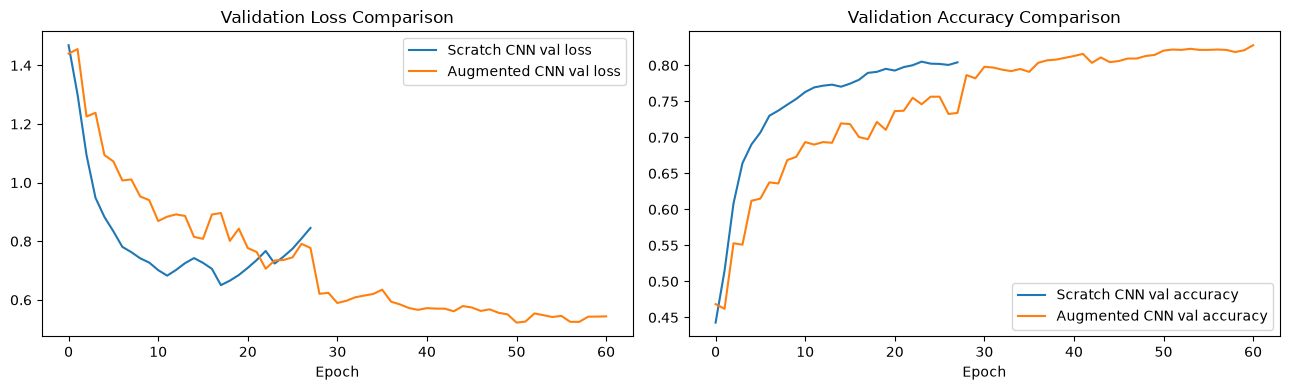

In [22]:
# Compare baseline and augmented training histories
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_cnn.history["val_loss"], label="Scratch CNN val loss")
axes[0].plot(history_aug.history["val_loss"], label="Augmented CNN val loss")
axes[0].set_title("Validation Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_cnn.history["val_accuracy"], label="Scratch CNN val accuracy")
axes[1].plot(history_aug.history["val_accuracy"], label="Augmented CNN val accuracy")
axes[1].set_title("Validation Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

In [23]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

def build_keras_aug_cnn():
    inputs = keras.Input(shape=(32, 32, 3))
    x = data_augmentation(inputs)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="CNN_Keras_Augmentation")

model_keras_aug = build_keras_aug_cnn()
model_keras_aug.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history_keras_aug = model_keras_aug.fit(
    X_train, y_train_ohe,
    epochs=30, batch_size=64,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
    ],
    verbose=1
)
keras_aug_loss, keras_aug_accuracy = model_keras_aug.evaluate(X_test, y_test_ohe, verbose=0)
print(f"CNN + Keras augmentation test accuracy: {keras_aug_accuracy:.4f} ({keras_aug_accuracy*100:.2f}%)")

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.2864 - loss: 1.8687 - val_accuracy: 0.3078 - val_loss: 1.8798 - learning_rate: 0.0010
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.4272 - loss: 1.5534 - val_accuracy: 0.3848 - val_loss: 1.7153 - learning_rate: 0.0010
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.4798 - loss: 1.4131 - val_accuracy: 0.4270 - val_loss: 1.6085 - learning_rate: 0.0010
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5201 - loss: 1.3169 - val_accuracy: 0.4912 - val_loss: 1.4390 - learning_rate: 0.0010
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5558 - loss: 1.2374 - val_accuracy: 0.5010 - val_loss: 1.4955 - learning_rate: 0.0010
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5748 - loss: 1.1847 - val_accuracy: 0.5452 - val_loss: 1.3488 - learning_rate: 0.0010
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 42ms/step - accuracy: 0.5922 - l

In [24]:
# A6.2 MobileNetV2 feature extraction
# CIFAR-10 images are resized to 96 x 96 to meet MobileNetV2's minimum input size.
X_train_r = tf.image.resize(X_train, (96, 96)).numpy()
X_test_r = tf.image.resize(X_test, (96, 96)).numpy()

# MobileNetV2 pretrained weights expect their own preprocessing scale [-1, 1].
X_train_mn = keras.applications.mobilenet_v2.preprocess_input(X_train_r * 255.0)
X_test_mn = keras.applications.mobilenet_v2.preprocess_input(X_test_r * 255.0)

base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(96, 96, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)
model_fe = keras.Model(inputs, outputs, name="MobileNetV2_Feature_Extraction")

model_fe.summary()
print("Total parameters:", model_fe.count_params())
print("Trainable parameters:", sum(np.prod(v.shape) for v in model_fe.trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step


Model: "MobileNetV2_Feature_Extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total parameters: 2423242
Trainable parameters: 165258


In [ ]:
# A6.3 Train feature-extraction head
model_fe.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_fe = model_fe.fit(
    X_train_mn, y_train_ohe,
    epochs=20, batch_size=64,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
    ],
    verbose=1
)
fe_loss, fe_accuracy = model_fe.evaluate(X_test_mn, y_test_ohe, verbose=1)
print(f"MobileNetV2 feature extraction test accuracy: {fe_accuracy:.4f} ({fe_accuracy*100:.2f}%)")

Epoch 1/20
 21/704 ━━━━━━━━━━━━━━━━━━━━ 11:24 1s/step - accuracy: 0.5246 - loss: 1.3945

In [ ]:
# A6.4 Fine-tune the top 30 layers at a very low learning rate
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for more stable fine-tuning on a small dataset.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_fe.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_ft = model_fe.fit(
    X_train_mn, y_train_ohe,
    epochs=10, batch_size=32,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7)
    ],
    verbose=1
)
ft_loss, ft_accuracy = model_fe.evaluate(X_test_mn, y_test_ohe, verbose=1)
print(f"MobileNetV2 fine-tuned test accuracy: {ft_accuracy:.4f} ({ft_accuracy*100:.2f}%)")

In [ ]:
# Plot feature extraction and fine-tuning histories with a vertical boundary
fe_val_acc = history_fe.history["val_accuracy"]
ft_val_acc = history_ft.history["val_accuracy"]
fe_val_loss = history_fe.history["val_loss"]
ft_val_loss = history_ft.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(1, len(fe_val_loss)+1), fe_val_loss, label="Feature extraction")
axes[0].plot(range(len(fe_val_loss)+1, len(fe_val_loss)+len(ft_val_loss)+1), ft_val_loss, label="Fine-tuning")
axes[0].axvline(len(fe_val_loss)+0.5, linestyle="--", label="Fine-tuning starts")
axes[0].set_title("MobileNetV2 Validation Loss")
axes[0].set_xlabel("Combined epoch")
axes[0].legend()

axes[1].plot(range(1, len(fe_val_acc)+1), fe_val_acc, label="Feature extraction")
axes[1].plot(range(len(fe_val_acc)+1, len(fe_val_acc)+len(ft_val_acc)+1), ft_val_acc, label="Fine-tuning")
axes[1].axvline(len(fe_val_acc)+0.5, linestyle="--", label="Fine-tuning starts")
axes[1].set_title("MobileNetV2 Validation Accuracy")
axes[1].set_xlabel("Combined epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# A6.5 Compare the six required approaches.
# LeNet-5 is trained here so the table contains a measured result rather than a placeholder.
lenet5.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history_lenet = lenet5.fit(
    X_train, y_train_ohe,
    epochs=15, batch_size=64,
    validation_split=0.1,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=1
)
lenet_loss, lenet_accuracy = lenet5.evaluate(X_test, y_test_ohe, verbose=0)

# Evaluate all models on the same test set where applicable
scratch_loss, scratch_acc = model_cnn.evaluate(X_test, y_test_ohe, verbose=0)
img_aug_loss, img_aug_acc = model_aug.evaluate(X_test, y_test_ohe, verbose=0)
keras_aug_loss, keras_aug_acc = model_keras_aug.evaluate(X_test, y_test_ohe, verbose=0)
fe_loss, fe_accuracy = model_fe.evaluate(X_test_mn, y_test_ohe, verbose=0)

results = pd.DataFrame([
    {"Model": "LeNet-5", "Architecture": "Classic CNN", "Augmentation": "No", "Transfer Learning": "No",
     "Test Accuracy": lenet_accuracy, "Parameters": lenet5.count_params()},
    {"Model": "CNN Scratch No Aug", "Architecture": "Custom CNN", "Augmentation": "No", "Transfer Learning": "No",
     "Test Accuracy": scratch_acc, "Parameters": model_cnn.count_params()},
    {"Model": "CNN Scratch + ImageDataGenerator", "Architecture": "Custom CNN", "Augmentation": "Yes", "Transfer Learning": "No",
     "Test Accuracy": img_aug_acc, "Parameters": model_aug.count_params()},
    {"Model": "CNN + Keras Augmentation", "Architecture": "Custom CNN", "Augmentation": "Yes", "Transfer Learning": "No",
     "Test Accuracy": keras_aug_acc, "Parameters": model_keras_aug.count_params()},
    {"Model": "MobileNetV2 Feature Extraction", "Architecture": "MobileNetV2 + head", "Augmentation": "No", "Transfer Learning": "Feature extraction",
     "Test Accuracy": fe_accuracy, "Parameters": model_fe.count_params()},
    {"Model": "MobileNetV2 Fine-Tuned", "Architecture": "MobileNetV2 + head", "Augmentation": "No", "Transfer Learning": "Fine-tuning",
     "Test Accuracy": ft_accuracy, "Parameters": model_fe.count_params()}
])
display(results.style.highlight_max(subset=["Test Accuracy"], color="lightgreen").format({"Test Accuracy": "{:.2%}"}))

In [ ]:
# A6.6 A small residual block using the Functional API
res_inputs = keras.Input(shape=(32, 32, 64), name="residual_input")

# Main path
x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(res_inputs)
x = layers.Conv2D(64, (3, 3), padding="same")(x)

# Shortcut path: 1x1 convolution keeps dimensions aligned and can project channels
shortcut = layers.Conv2D(64, (1, 1), padding="same")(res_inputs)

x = layers.Add()([x, shortcut])
res_outputs = layers.Activation("relu")(x)
residual_block = keras.Model(res_inputs, res_outputs, name="Residual_Block_Demo")
residual_block.summary()

In [ ]:
# Create output folders
os.makedirs("plots", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Save the main model and comparison models
model_cnn.save("models/cifar10_cnn_scratch.keras")
model_aug.save("models/cifar10_cnn_imgdatagen.keras")
model_keras_aug.save("models/cifar10_cnn_keras_aug.keras")
lenet5.save("models/cifar10_lenet5.keras")
model_fe.save("models/cifar10_mobilenetv2_finetuned.keras")

results.to_csv("cifar10_model_comparison.csv", index=False)
print("Saved models in ./models and results to cifar10_model_comparison.csv")

In [ ]:
# Save core plots for the GitHub repository
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_cnn.history["loss"], label="Train")
axes[0].plot(history_cnn.history["val_loss"], label="Validation")
axes[0].set_title("Scratch CNN Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history_cnn.history["accuracy"], label="Train")
axes[1].plot(history_cnn.history["val_accuracy"], label="Validation")
axes[1].set_title("Scratch CNN Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig("plots/cnn_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False
)
plt.tight_layout()
plt.savefig("plots/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

results_plot = results.sort_values("Test Accuracy", ascending=True)
plt.figure(figsize=(10, 5))
plt.barh(results_plot["Model"], results_plot["Test Accuracy"])
plt.xlabel("Test accuracy")
plt.title("CIFAR-10 Model Comparison")
plt.tight_layout()
plt.savefig("plots/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("Plots saved in ./plots")